In [1]:
import os
from torchvision import datasets, transforms
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import time
import torchvision.models as models
from matplotlib import pyplot as plt

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


### Load Data

In [3]:
image_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.25, contrast=0.25),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [5]:
dataset = datasets.ImageFolder(root="./dataset", transform=image_transforms)

In [6]:
len(dataset)

2300

In [21]:
class_names = dataset.classes
class_names

['F_Breakage', 'F_Crushed', 'F_Normal', 'R_Breakage', 'R_Crushed', 'R_Normal']

In [8]:
num_classes = len(dataset.classes)
num_classes

6

In [9]:
train_size = int(0.75 * len(dataset))
val_size = len(dataset) - train_size
train_size, val_size

(1725, 575)

In [10]:
from torch.utils.data import random_split

train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

In [11]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

In [12]:
for images, labels in train_loader:
    print(images.shape)
    print(labels.shape)
    break

torch.Size([32, 3, 224, 224])
torch.Size([32])


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9637812..1.3502399].


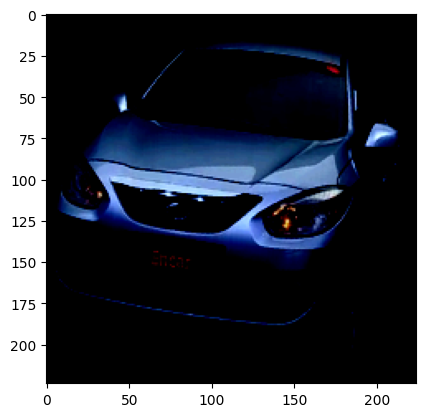

In [13]:
plt.imshow(images[0].permute(1,2,0))

In [14]:
class CarClassifier(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1), # 16, 224, 224
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=0), #16, 112, 112
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1), #32, 112, 112
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=0), #32, 56, 56
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1), #64, 56, 56
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=0), #64, 28, 28

            nn.Flatten(),
            nn.Linear(64*28*28, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, num_classes)
        )
    def forward(self, x):
        x = self.network(x)
        return x

In [15]:
model = CarClassifier(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [14]:
def train_model(model, criterion, optimizer, epochs=5):
    start = time.time()
    for epoch in range(epochs):
        model.train()
        running_loss=0

        for batch_no, (images, labels) in enumerate(train_loader):
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            if((batch_no + 1) % 10 == 0):
                print(f"Batch : {batch_no+1}, Epoch : {epoch+1}, Loss : {loss.item():0.4f}")

            running_loss+=loss.item() * images.size(0)

        epoch_loss = running_loss/len(train_loader.dataset)

        print(f"Epoch : {epoch+1}/{epochs}, Avg_Loss : {epoch_loss:0.4f}")

        # VALIDATION
        model.eval()
        correct = 0
        total = 0
        all_labels = []
        all_predictions = []
        with torch.no_grad():

            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                _, predicted = torch.max(outputs.data, 1)

                total+= labels.size(0)
                correct += (predicted == labels).sum().item()

                all_labels.extend(labels.cpu().numpy())
                all_predictions.extend(predicted.cpu().numpy())
            print(f"-----Accuracy : {100 * correct /total:.2f} -----")
    end = time.time()

    print(f"Execution time : {end-start} seconds")

    return all_labels, all_predictions

In [17]:
all_labels, all_predictions = train_model(model, criterion, optimizer, 10)

Batch : 10, Epoch : 1, Loss : 1.7801
Batch : 20, Epoch : 1, Loss : 1.7850
Batch : 30, Epoch : 1, Loss : 1.5322
Batch : 40, Epoch : 1, Loss : 1.6540
Batch : 50, Epoch : 1, Loss : 1.5595
Epoch : 1/10, Avg_Loss : 1.6490
-----Accuracy : 44.87 -----
Batch : 10, Epoch : 2, Loss : 1.4196
Batch : 20, Epoch : 2, Loss : 1.0042
Batch : 30, Epoch : 2, Loss : 0.7351
Batch : 40, Epoch : 2, Loss : 0.9549
Batch : 50, Epoch : 2, Loss : 0.9791
Epoch : 2/10, Avg_Loss : 1.1020
-----Accuracy : 52.00 -----
Batch : 10, Epoch : 3, Loss : 0.9960
Batch : 20, Epoch : 3, Loss : 0.9368
Batch : 30, Epoch : 3, Loss : 0.8384
Batch : 40, Epoch : 3, Loss : 0.8808
Batch : 50, Epoch : 3, Loss : 1.0641
Epoch : 3/10, Avg_Loss : 0.9923
-----Accuracy : 54.09 -----
Batch : 10, Epoch : 4, Loss : 1.0132
Batch : 20, Epoch : 4, Loss : 0.9521
Batch : 30, Epoch : 4, Loss : 0.8264
Batch : 40, Epoch : 4, Loss : 0.9392
Batch : 50, Epoch : 4, Loss : 1.0092
Epoch : 4/10, Avg_Loss : 0.9413
-----Accuracy : 54.09 -----
Batch : 10, Epoch : 

### Model 2 with Regularization

In [ ]:
class CarClassifierwithRegularization(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1), # 16, 224, 224
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=0), #16, 112, 112
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1), #32, 112, 112
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=0), #32, 56, 56
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1), #64, 56, 56
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=0), #64, 28, 28

            nn.Flatten(),
            nn.Linear(64*28*28, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes)
        )
    def forward(self, x):
        x = self.network(x)
        return x

In [19]:
model_with_reg = CarClassifierwithRegularization(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer_with_reg = optim.Adam(model_with_reg.parameters(), lr=0.001)

In [20]:
train_model(model_with_reg, criterion, optimizer_with_reg, 10)

Batch : 10, Epoch : 1, Loss : 3.6984
Batch : 20, Epoch : 1, Loss : 2.9011
Batch : 30, Epoch : 1, Loss : 1.3103
Batch : 40, Epoch : 1, Loss : 1.6309
Batch : 50, Epoch : 1, Loss : 1.4569
Epoch : 1/10, Avg_Loss : 2.6786
-----Accuracy : 43.83 -----
Batch : 10, Epoch : 2, Loss : 1.4414
Batch : 20, Epoch : 2, Loss : 0.9173
Batch : 30, Epoch : 2, Loss : 1.1369
Batch : 40, Epoch : 2, Loss : 0.9851
Batch : 50, Epoch : 2, Loss : 0.9174
Epoch : 2/10, Avg_Loss : 1.1872
-----Accuracy : 45.39 -----
Batch : 10, Epoch : 3, Loss : 0.9320
Batch : 20, Epoch : 3, Loss : 1.2581
Batch : 30, Epoch : 3, Loss : 1.0297
Batch : 40, Epoch : 3, Loss : 1.3276
Batch : 50, Epoch : 3, Loss : 1.0552
Epoch : 3/10, Avg_Loss : 1.0824
-----Accuracy : 45.39 -----
Batch : 10, Epoch : 4, Loss : 1.3095
Batch : 20, Epoch : 4, Loss : 0.8570
Batch : 30, Epoch : 4, Loss : 1.0882
Batch : 40, Epoch : 4, Loss : 1.0523
Batch : 50, Epoch : 4, Loss : 1.0225
Epoch : 4/10, Avg_Loss : 1.0596
-----Accuracy : 46.96 -----
Batch : 10, Epoch : 

([np.int64(0),
  np.int64(5),
  np.int64(5),
  np.int64(3),
  np.int64(4),
  np.int64(0),
  np.int64(5),
  np.int64(1),
  np.int64(2),
  np.int64(5),
  np.int64(5),
  np.int64(5),
  np.int64(2),
  np.int64(2),
  np.int64(2),
  np.int64(5),
  np.int64(2),
  np.int64(0),
  np.int64(1),
  np.int64(1),
  np.int64(2),
  np.int64(0),
  np.int64(2),
  np.int64(0),
  np.int64(5),
  np.int64(2),
  np.int64(0),
  np.int64(0),
  np.int64(1),
  np.int64(5),
  np.int64(1),
  np.int64(1),
  np.int64(5),
  np.int64(2),
  np.int64(0),
  np.int64(3),
  np.int64(1),
  np.int64(0),
  np.int64(0),
  np.int64(5),
  np.int64(4),
  np.int64(3),
  np.int64(5),
  np.int64(2),
  np.int64(2),
  np.int64(2),
  np.int64(1),
  np.int64(2),
  np.int64(1),
  np.int64(1),
  np.int64(0),
  np.int64(1),
  np.int64(0),
  np.int64(3),
  np.int64(0),
  np.int64(4),
  np.int64(0),
  np.int64(3),
  np.int64(3),
  np.int64(5),
  np.int64(1),
  np.int64(0),
  np.int64(1),
  np.int64(3),
  np.int64(3),
  np.int64(0),
  np.int64

### Model 3 EfficientNet

In [26]:
model = models.efficientnet_b0(weights='DEFAULT')
print(model.classifier)

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=1000, bias=True)
)


In [27]:
class CarClassifierEfficinetNet(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.model = models.efficientnet_b0(weights='DEFAULT')

        for param in self.model.parameters():
            param.requires_grad = False

        in_features = self.model.classifier[1].in_features

        self.model.classifier = nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(in_features, num_classes)
        )

    def forward(self, x):
        x = self.model(x)
        return x

In [29]:
model_efficientnet = CarClassifierEfficinetNet(num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer_efficientnet = optim.Adam(filter(lambda p : p.requires_grad, model_efficientnet.parameters()), lr=0.001)

train_model(model_efficientnet, criterion, optimizer_efficientnet, epochs=10)

Batch : 10, Epoch : 1, Loss : 1.4769
Batch : 20, Epoch : 1, Loss : 1.4338
Batch : 30, Epoch : 1, Loss : 1.2075
Batch : 40, Epoch : 1, Loss : 1.2766
Batch : 50, Epoch : 1, Loss : 1.1908
Epoch : 1/10, Avg_Loss : 1.4145
-----Accuracy : 55.65 -----
Batch : 10, Epoch : 2, Loss : 1.2269
Batch : 20, Epoch : 2, Loss : 1.0744
Batch : 30, Epoch : 2, Loss : 0.9891
Batch : 40, Epoch : 2, Loss : 0.9862
Batch : 50, Epoch : 2, Loss : 1.0064
Epoch : 2/10, Avg_Loss : 1.0594
-----Accuracy : 62.43 -----
Batch : 10, Epoch : 3, Loss : 0.9398
Batch : 20, Epoch : 3, Loss : 0.8410
Batch : 30, Epoch : 3, Loss : 0.9406
Batch : 40, Epoch : 3, Loss : 0.8738
Batch : 50, Epoch : 3, Loss : 0.9023
Epoch : 3/10, Avg_Loss : 0.9472
-----Accuracy : 60.87 -----
Batch : 10, Epoch : 4, Loss : 1.1173
Batch : 20, Epoch : 4, Loss : 0.8515
Batch : 30, Epoch : 4, Loss : 0.9940
Batch : 40, Epoch : 4, Loss : 0.7150
Batch : 50, Epoch : 4, Loss : 0.6832
Epoch : 4/10, Avg_Loss : 0.8803
-----Accuracy : 62.96 -----
Batch : 10, Epoch : 

([np.int64(0),
  np.int64(5),
  np.int64(5),
  np.int64(3),
  np.int64(4),
  np.int64(0),
  np.int64(5),
  np.int64(1),
  np.int64(2),
  np.int64(5),
  np.int64(5),
  np.int64(5),
  np.int64(2),
  np.int64(2),
  np.int64(2),
  np.int64(5),
  np.int64(2),
  np.int64(0),
  np.int64(1),
  np.int64(1),
  np.int64(2),
  np.int64(0),
  np.int64(2),
  np.int64(0),
  np.int64(5),
  np.int64(2),
  np.int64(0),
  np.int64(0),
  np.int64(1),
  np.int64(5),
  np.int64(1),
  np.int64(1),
  np.int64(5),
  np.int64(2),
  np.int64(0),
  np.int64(3),
  np.int64(1),
  np.int64(0),
  np.int64(0),
  np.int64(5),
  np.int64(4),
  np.int64(3),
  np.int64(5),
  np.int64(2),
  np.int64(2),
  np.int64(2),
  np.int64(1),
  np.int64(2),
  np.int64(1),
  np.int64(1),
  np.int64(0),
  np.int64(1),
  np.int64(0),
  np.int64(3),
  np.int64(0),
  np.int64(4),
  np.int64(0),
  np.int64(3),
  np.int64(3),
  np.int64(5),
  np.int64(1),
  np.int64(0),
  np.int64(1),
  np.int64(3),
  np.int64(3),
  np.int64(0),
  np.int64

### Model 4 ResNet

In [32]:
class CarClassifierResNet(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.model = models.resnet50(weights='DEFAULT')

        for param in self.model.parameters():
            param.requires_grad = False

        for param in self.model.layer4.parameters():
            param.requires_grad = True


        self.model.fc = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(self.model.fc.in_features, num_classes)
        )

    def forward(self, x):
        x = self.model(x)
        return x

In [33]:
model_resnet = CarClassifierResNet(num_classes).to(device)

criterion = nn.CrossEntropyLoss()

optimizer_resnet = optim.Adam(filter(lambda p : p.requires_grad, model_resnet.parameters()), lr=0.001)


labels, predictions = train_model(model_resnet, criterion, optimizer_resnet, 10)

Batch : 10, Epoch : 1, Loss : 0.9537
Batch : 20, Epoch : 1, Loss : 0.9323
Batch : 30, Epoch : 1, Loss : 0.9411
Batch : 40, Epoch : 1, Loss : 0.7128
Batch : 50, Epoch : 1, Loss : 0.8350
Epoch : 1/10, Avg_Loss : 0.8957
-----Accuracy : 71.30 -----
Batch : 10, Epoch : 2, Loss : 0.4008
Batch : 20, Epoch : 2, Loss : 0.5516
Batch : 30, Epoch : 2, Loss : 0.5569
Batch : 40, Epoch : 2, Loss : 0.8078
Batch : 50, Epoch : 2, Loss : 0.4606
Epoch : 2/10, Avg_Loss : 0.5197
-----Accuracy : 77.91 -----
Batch : 10, Epoch : 3, Loss : 0.3718
Batch : 20, Epoch : 3, Loss : 0.4265
Batch : 30, Epoch : 3, Loss : 0.5430
Batch : 40, Epoch : 3, Loss : 0.4230
Batch : 50, Epoch : 3, Loss : 0.3568
Epoch : 3/10, Avg_Loss : 0.3716
-----Accuracy : 76.17 -----
Batch : 10, Epoch : 4, Loss : 0.3456
Batch : 20, Epoch : 4, Loss : 0.2692
Batch : 30, Epoch : 4, Loss : 0.1447
Batch : 40, Epoch : 4, Loss : 0.1829
Batch : 50, Epoch : 4, Loss : 0.2084
Epoch : 4/10, Avg_Loss : 0.2814
-----Accuracy : 78.43 -----
Batch : 10, Epoch : 

#### I ran hyperparameter tunning in another notebook and figured that the best parameters for resnet models are (1) Dropout rate = 0.2 (2) Learning Rate = 0.005

So now let's train the model once again with these best parameters

In [15]:
# Load the pre-trained ResNet model
class CarClassifierResNet(nn.Module):
    def __init__(self, num_classes, dropout_rate=0.5):
        super().__init__()
        self.model = models.resnet50(weights='DEFAULT')
        # Freeze all layers except the final fully connected layer
        for param in self.model.parameters():
            param.requires_grad = False
            
        # Unfreeze layer4 and fc layers
        for param in self.model.layer4.parameters():
            param.requires_grad = True            
            
        # Replace the final fully connected layer
        self.model.fc = nn.Sequential(
            nn.Dropout(dropout_rate),
            nn.Linear(self.model.fc.in_features, num_classes)
        )

    def forward(self, x):
        x = self.model(x)
        return x


model = CarClassifierResNet(num_classes=num_classes, dropout_rate=0.2).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.005)

labels, predictions = train_model(model, criterion, optimizer, epochs=10)

Batch : 10, Epoch : 1, Loss : 0.7796
Batch : 20, Epoch : 1, Loss : 0.6661
Batch : 30, Epoch : 1, Loss : 0.6337
Batch : 40, Epoch : 1, Loss : 0.6666
Batch : 50, Epoch : 1, Loss : 0.5551
Epoch : 1/10, Avg_Loss : 0.8846
-----Accuracy : 72.70 -----
Batch : 10, Epoch : 2, Loss : 0.4716
Batch : 20, Epoch : 2, Loss : 0.6733
Batch : 30, Epoch : 2, Loss : 0.6092
Batch : 40, Epoch : 2, Loss : 0.5624
Batch : 50, Epoch : 2, Loss : 0.5616
Epoch : 2/10, Avg_Loss : 0.5111
-----Accuracy : 77.39 -----
Batch : 10, Epoch : 3, Loss : 0.2820
Batch : 20, Epoch : 3, Loss : 0.6218
Batch : 30, Epoch : 3, Loss : 0.3039
Batch : 40, Epoch : 3, Loss : 0.2714
Batch : 50, Epoch : 3, Loss : 0.4335
Epoch : 3/10, Avg_Loss : 0.4037
-----Accuracy : 77.22 -----
Batch : 10, Epoch : 4, Loss : 0.2408
Batch : 20, Epoch : 4, Loss : 0.2669
Batch : 30, Epoch : 4, Loss : 0.3691
Batch : 40, Epoch : 4, Loss : 0.1564
Batch : 50, Epoch : 4, Loss : 0.2958
Epoch : 4/10, Avg_Loss : 0.3528
-----Accuracy : 65.57 -----
Batch : 10, Epoch : 

### Model Evaluation using Confusion Matrix and Classification Report

In [16]:
from sklearn.metrics import classification_report

report = classification_report(labels, predictions)
print(report)

              precision    recall  f1-score   support

           0       0.82      0.82      0.82       113
           1       0.80      0.73      0.76       111
           2       0.84      0.93      0.89       105
           3       0.75      0.79      0.77        82
           4       0.70      0.78      0.74        88
           5       0.90      0.70      0.79        76

    accuracy                           0.80       575
   macro avg       0.80      0.79      0.79       575
weighted avg       0.80      0.80      0.80       575



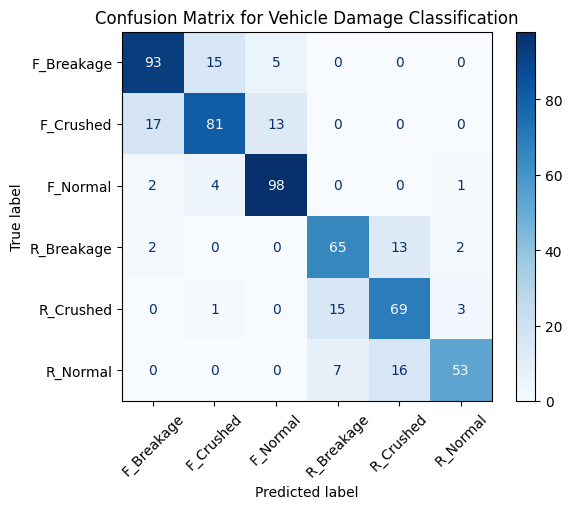

In [19]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from matplotlib import pyplot as plt

conf_matrix = confusion_matrix(labels, predictions, labels=np.arange(num_classes))
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=class_names)
disp.plot(cmap=plt.cm.Blues, xticks_rotation=45)
plt.title("Confusion Matrix for Vehicle Damage Classification")
plt.show()

### Save the Model

In [20]:
torch.save(model.state_dict(), 'saved_model.pth')